# 1. Load saved data and look at one tree

Mounted at /content/drive
number of trees: 562
first five names: [np.str_('R01N01'), np.str_('R01N02'), np.str_('R01N03'), np.str_('R01N04'), np.str_('R01N05')]
X shape: (562, 128, 128, 4)
Y shape: (562, 256, 256)


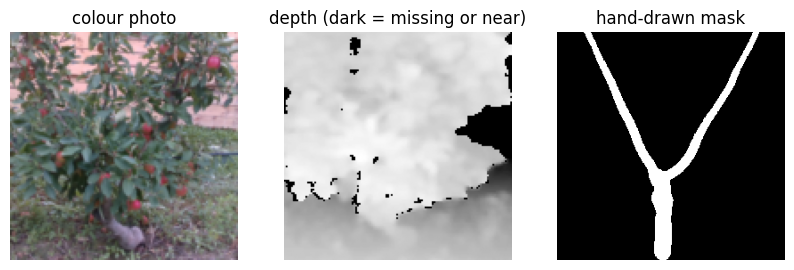

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt

c = np.load("/content/drive/MyDrive/apple_cache.npz", allow_pickle=True)
trees = list(c["trees"])   # tree names, like R01N01
X = c["Xc"]                # the images: RGB + depth, shrunk to 128 x 128
Y = c["Y"]                 # the hand-drawn masks, 256 x 256

print("number of trees:", len(trees))
print("first five names:", trees[:5])
print("X shape:", X.shape)
print("Y shape:", Y.shape)

i = 0   # change this number to look at a different tree
fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
ax[0].imshow(X[i, :, :, :3]);        ax[0].set_title("colour photo")
ax[1].imshow(X[i, :, :, 3], cmap="gray"); ax[1].set_title("depth (dark = missing or near)")
ax[2].imshow(Y[i], cmap="gray");     ax[2].set_title("hand-drawn mask")
for a in ax: a.axis("off")
plt.show()

**What the lines do**

*drive.mount* lets Colab read your
Google Drive.

*np.load* opens the saved file. It holds the names (trees), the images (Xc) and the masks (Y).

*X.shape* is how many numbers each array has. (562, 128, 128, 4) means 562 trees, each 128×128 pixels, with 4 layers (red, green, blue, depth).

The plot shows the colour photo, the depth image and the mask for tree number 0.

# 2. Split the trees into train, validation and test

We need to measure how well a model works on trees it has never seen, so we split the 562 trees into three groups:

Train: the model learns from these.

Validation: we tune small choices here, like the threshold.

Test: used once at the end for the final score.

In [3]:
def row_of(name):
    return int(name[1:name.index("N")])        # "R03N12" -> 3

rows = np.array([row_of(t) for t in trees])
print("number of rows:", len(set(rows)))

def split_by_rows(ids, seed=0, test_frac=0.20, val_frac=0.15):
    r = np.array([row_of(t) for t in ids])
    all_rows = sorted(set(r))
    n = len(all_rows)
    n_test = int(np.floor(test_frac * n + 1e-9))
    n_val_end = int(np.floor((test_frac + val_frac) * n + 1e-9))
    shuffled = np.random.default_rng(seed).permutation(all_rows)   # shuffle the row numbers
    te = np.where(np.isin(r, shuffled[:n_test]))[0]
    va = np.where(np.isin(r, shuffled[n_test:n_val_end]))[0]
    tr = np.setdiff1d(np.arange(len(r)), np.concatenate([te, va]))
    return tr, va, te

tr, va, te = split_by_rows(trees, seed=0)
print("train / validation / test trees:", len(tr), len(va), len(te))
print("test rows:", sorted(int(x) for x in set(rows[te])))
print("rows in both train and test:", set(rows[tr]) & set(rows[te]))

number of rows: 20
train / validation / test trees: 382 74 106
test rows: [3, 5, 7, 20]
rows in both train and test: set()


**What the lines do**

*row_of* pulls the row number out of a name.

*split_by_rows* shuffles the row numbers (with a fixed seed so you get the same shuffle every time), gives 20% of the rows to test and 15% to validation, and everything else to training. tr, va and te are lists of tree positions.

The last line is a safety check: the rows in both train and test should be empty.

# 3. the baseline that ignores the photo

Before building a clever model, we need a baseline to beat. The simplest guess is: “every tree looks roughly like the average tree”. Here’s how:

1. Take all the training masks and average them. Each pixel then holds the fraction of training trees that had a branch there (0 = never, 1 = always).
2. Turn that average into a black and white mask by choosing a threshold: pixels above it become white.
3. Use that same mask as the prediction for every tree. It never looks at the photo.

How we score it: Dice. For a predicted mask and the true mask:

Dice = 2 × (pixels white in both) ÷ (white pixels in the prediction + white pixels in the truth)

It is 1 if they match perfectly and 0 if they don’t overlap at all. The branches are thin (only about 7% of the pixels), so even a decent guess scores well below 1.

How to pick the threshold: we try many values and keep the one with the best Dice on the validation trees. Then we score the test trees once. The test trees never influence the choice.

best threshold (chosen on validation): 0.15
test Dice: 0.371 +/- 0.087  (over 106 test trees)


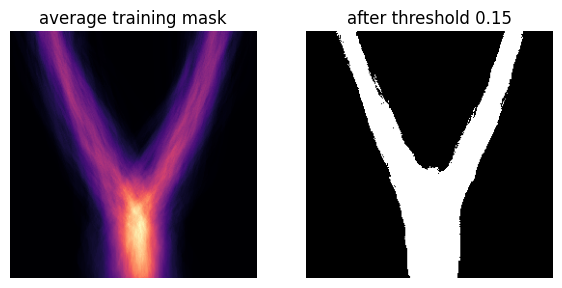

In [4]:
Yb = Y > 0                      # make the masks True/False

def dice(pred, gt):
    total = pred.sum() + gt.sum()
    return 1.0 if total == 0 else 2 * (pred & gt).sum() / total

mean_mask = Yb[tr].mean(axis=0)            # average of the TRAINING masks only
thresholds = np.linspace(0.05, 0.9, 18)

def mean_dice(thr, ids):
    return np.mean([dice(mean_mask >= thr, Yb[i]) for i in ids])

val_scores = [mean_dice(t, va) for t in thresholds]      # choose threshold on validation trees
best_thr = thresholds[int(np.argmax(val_scores))]

test_scores = np.array([dice(mean_mask >= best_thr, Yb[i]) for i in te])
print(f"best threshold (chosen on validation): {best_thr:.2f}")
print(f"test Dice: {test_scores.mean():.3f} +/- {test_scores.std():.3f}  (over {len(te)} test trees)")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(mean_mask, cmap="magma"); ax[0].set_title("average training mask")
ax[1].imshow(mean_mask >= best_thr, cmap="gray"); ax[1].set_title(f"after threshold {best_thr:.2f}")
for a in ax: a.axis("off")
plt.show()

The “±” is how much the score varies from tree to tree. 0.371 is the number every real model has to beat.

# 4. compress each mask into a few numbers (the shape model)

A mask has 256×256 = 65,536 pixels, and predicting that many numbers from a photo is hard with only 382 training trees. But the masks are all similar Y shapes, so they can be described much more simply.

The idea:

- Find a few basic shapes such that any tree’s mask is approximately (average mask) + a mix of those basic shapes.
- The mix is just a short list of numbers, one per basic shape (for example, “a bit more lean to the left, a bit wider fork”).
- The maths tool that finds these shapes is the SVD (singular value decomposition), the first of the numerical methods you use in this unit.
- K is how many basic shapes we keep. Larger K describes masks more exactly.

The point of this step is a ceiling. If we could predict the mix numbers perfectly from the photo, how good would the masks be? That tells us the best this approach could ever do. To keep things fast, we first shrink the masks to 64×64.

share of the variation explained by the first 1, 2, 5, 20 shapes: [0.09, 0.14, 0.26, 0.51]


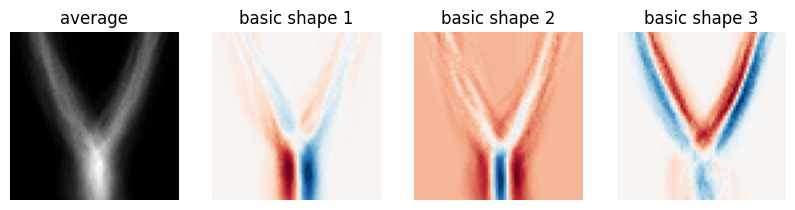

K=  1: test Dice if the mix numbers were perfect = 0.259
K=  2: test Dice if the mix numbers were perfect = 0.366
K=  5: test Dice if the mix numbers were perfect = 0.425
K= 10: test Dice if the mix numbers were perfect = 0.544
K= 20: test Dice if the mix numbers were perfect = 0.666
K= 50: test Dice if the mix numbers were perfect = 0.794


In [5]:
from scipy.ndimage import zoom

def small(Y, s=64):
    n, h, _ = Y.shape
    f = h // s
    return (Y.reshape(n, s, f, s, f).mean(axis=(2, 4)) > 0.5).reshape(n, -1).astype(float)

M = small(Y)                           # each mask becomes a row of 64*64 = 4096 numbers
M_tr = M[tr]
mu = M_tr.mean(axis=0)                 # the average mask
U, S, Vt = np.linalg.svd(M_tr - mu, full_matrices=False)   # Vt holds the basic shapes
share = S**2 / (S**2).sum()
print("share of the variation explained by the first 1, 2, 5, 20 shapes:",
      [round(float(share[:k].sum()), 2) for k in (1, 2, 5, 20)])

fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
ax[0].imshow(mu.reshape(64, 64), cmap="gray"); ax[0].set_title("average")
for j in range(3):
    ax[j + 1].imshow(Vt[j].reshape(64, 64), cmap="RdBu"); ax[j + 1].set_title(f"basic shape {j + 1}")
for a in ax: a.axis("off")
plt.show()

def rebuild(ids, K):                   # mask from its first K mix numbers
    comp = Vt[:K]
    coef = (M[ids] - mu) @ comp.T
    P = mu + coef @ comp
    return np.stack([zoom(p.reshape(64, 64), 4, order=1) for p in P])

for K in (1, 2, 5, 10, 20, 50):
    P = rebuild(te, K)
    d = np.mean([dice(P[j] >= 0.5, Yb[i]) for j, i in enumerate(te)])
    print(f"K={K:3d}: test Dice if the mix numbers were perfect = {d:.3f}")

- Basic shape 1 (red and blue on either side of the trunk) is the trunk leaning left or right.
- Basic shape 2 (whole picture shaded, trunk stripe) is how thick the whole tree is.
- Basic shape 3 (red/blue on the arms) is how wide the fork is.

# 5. predict the mix numbers from the photo (ridge regression)

Now the model that actually looks at the picture. Train it to turn a photo into the K = 20 mix numbers from Step 4.

1. Shrink the photo into features. Each tree’s four layers (red, green, blue, depth) are averaged over a 16×16 grid of blocks. That’s 16 × 16 × 4 = 1,024 numbers per tree, a blurry summary of the photo.
2. Fit a formula. For each of the 20 mix numbers, learn a weighted sum of the 1,024 features that predicts it. This is ridge regression, a numerical method from your unit. Ridge adds a penalty, alpha, that stops the weights growing too large, which protects against memorising the 382 training trees (overfitting).
3. Predict, rebuild and score. For a new tree: features → mix numbers → rebuilt mask → threshold → Dice. As before, we pick the threshold on the validation trees and score the test trees once.

The solve line in the code is the “dual form”. With 382 trees and 1,024 features, it solves a 382×382 system instead of a 1,024×1,024 one, which is cheaper.

In [6]:
def pool(X, grid=16):
    a = X.astype(np.float32) / 255
    n, h, w, k = a.shape
    f = h // grid
    return a.reshape(n, grid, f, grid, f, k).mean(axis=(2, 4)).reshape(n, -1)

F = pool(X)
print("features per tree:", F.shape[1])

K, alpha = 20, 1e4
comp = Vt[:K]                                # the K basic shapes
C = (M[tr] - mu) @ comp.T                    # the answers: mix numbers of the training trees
f_mean, f_std = F[tr].mean(0), F[tr].std(0) + 1e-6
A = (F[tr] - f_mean) / f_std                 # standardise the features
c_mean = C.mean(0)
coef = np.linalg.solve(A @ A.T + alpha * np.eye(len(A)), C - c_mean)
W = A.T @ coef                               # the learned weights (1024 x 20)

def predict(ids):
    mix = ((F[ids] - f_mean) / f_std) @ W + c_mean
    P = mu + mix @ comp
    return np.stack([zoom(p.reshape(64, 64), 4, order=1) for p in P])

P_va, P_te = predict(va), predict(te)
thresholds = np.linspace(0.05, 0.9, 18)
val_d = [np.mean([dice(P_va[j] >= t, Yb[i]) for j, i in enumerate(va)]) for t in thresholds]
thr = thresholds[int(np.argmax(val_d))]
d_te = np.array([dice(P_te[j] >= thr, Yb[i]) for j, i in enumerate(te)])

print(f"threshold chosen on validation: {thr:.2f}")
print(f"ridge test Dice: {d_te.mean():.3f} +/- {d_te.std():.3f}")
print(f"mean-mask baseline from Step 3: {test_scores.mean():.3f}")
print(f"gain over baseline: {d_te.mean() - test_scores.mean():+.3f}")

features per tree: 1024
threshold chosen on validation: 0.15
ridge test Dice: 0.405 +/- 0.077
mean-mask baseline from Step 3: 0.371
gain over baseline: +0.034


# 6. repeat on 10 different splits

We shuffle the rows with 10 different seeds, so each seed gives different train, validation and test rows, and rerun the whole comparison each time. This shows:

- the average gain, a more trustworthy number than any single split;

- whether ridge beats the baseline every time or only sometimes.

The code puts Steps 3 and 5 inside one function that takes a seed. Note that the shape model (SVD) is refitted for every split, using only that split’s training trees, so no test information leaks in.

In [7]:
thresholds = np.linspace(0.05, 0.9, 18)

def run_both(seed):
    tr_, va_, te_ = split_by_rows(trees, seed=seed)

    # baseline: average training mask
    mm = Yb[tr_].mean(axis=0)
    vb = [np.mean([dice(mm >= t, Yb[i]) for i in va_]) for t in thresholds]
    tb = thresholds[int(np.argmax(vb))]
    base = np.mean([dice(mm >= tb, Yb[i]) for i in te_])

    # ridge: shape model + regression, fitted on this split's training trees only
    M_tr = M[tr_]
    mu_ = M_tr.mean(axis=0)
    _, _, Vt_ = np.linalg.svd(M_tr - mu_, full_matrices=False)
    comp_ = Vt_[:20]
    C_ = (M_tr - mu_) @ comp_.T
    fm, fs = F[tr_].mean(0), F[tr_].std(0) + 1e-6
    A_ = (F[tr_] - fm) / fs
    cm = C_.mean(0)
    W_ = A_.T @ np.linalg.solve(A_ @ A_.T + 1e4 * np.eye(len(A_)), C_ - cm)

    def pred(ids):
        P = mu_ + (((F[ids] - fm) / fs) @ W_ + cm) @ comp_
        return np.stack([zoom(p.reshape(64, 64), 4, order=1) for p in P])

    Pv, Pt = pred(va_), pred(te_)
    vr = [np.mean([dice(Pv[j] >= t, Yb[i]) for j, i in enumerate(va_)]) for t in thresholds]
    tr_thr = thresholds[int(np.argmax(vr))]
    ridge = np.mean([dice(Pt[j] >= tr_thr, Yb[i]) for j, i in enumerate(te_)])
    return base, ridge

results = []
for seed in range(10):
    b, r = run_both(seed)
    results.append((b, r))
    print(f"seed {seed}: baseline {b:.3f}   ridge {r:.3f}   gain {r - b:+.3f}")

res = np.array(results)
gain = res[:, 1] - res[:, 0]
print(f"\nbaseline mean {res[:, 0].mean():.3f}   ridge mean {res[:, 1].mean():.3f}")
print(f"gain: mean {gain.mean():+.3f}, std {gain.std():.3f}, ridge better in {(gain > 0).sum()} of 10 splits")

seed 0: baseline 0.371   ridge 0.405   gain +0.034
seed 1: baseline 0.350   ridge 0.372   gain +0.022
seed 2: baseline 0.374   ridge 0.398   gain +0.023
seed 3: baseline 0.369   ridge 0.394   gain +0.025
seed 4: baseline 0.375   ridge 0.393   gain +0.018
seed 5: baseline 0.371   ridge 0.388   gain +0.017
seed 6: baseline 0.363   ridge 0.394   gain +0.031
seed 7: baseline 0.364   ridge 0.389   gain +0.025
seed 8: baseline 0.368   ridge 0.387   gain +0.019
seed 9: baseline 0.374   ridge 0.390   gain +0.016

baseline mean 0.368   ridge mean 0.391
gain: mean +0.023, std 0.006, ridge better in 10 of 10 splits


# 7. add the second and third scores (IoU and boundary F1)

Dice only measures how much the masks overlap, so a prediction that is two pixels off on a thin branch scores very badly. We add two more:

- IoU is overlap divided by the combined area of both masks. It’s stricter than Dice.
- Boundary F1 (3-pixel tolerance) checks whether the edges of the predicted mask lie within 3 pixels of the true edges. It is more forgiving of slight shifts and closer to what a robot needs.

Earlier, ridge raised Dice but lowered boundary F1, and this step checks whether that still holds with your numbers. It reruns the same 10 splits, so it takes a few minutes.

In [8]:
from scipy.ndimage import distance_transform_edt, binary_erosion

def iou(p, g):
    u = (p | g).sum()
    return 1.0 if u == 0 else (p & g).sum() / u

def edge(m):
    return m & ~binary_erosion(m, border_value=1)

def boundary_f1(p, g, tol=3):
    bp, bg = edge(p), edge(g)
    if not bp.any() and not bg.any(): return 1.0
    if not bp.any() or not bg.any(): return 0.0
    prec = (distance_transform_edt(~bg)[bp] <= tol).mean()
    rec = (distance_transform_edt(~bp)[bg] <= tol).mean()
    return 0.0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)

def scores(pred_masks, ids):
    d = np.mean([dice(p, Yb[i]) for p, i in zip(pred_masks, ids)])
    j = np.mean([iou(p, Yb[i]) for p, i in zip(pred_masks, ids)])
    b = np.mean([boundary_f1(p, Yb[i]) for p, i in zip(pred_masks, ids)])
    return d, j, b

def run_full(seed):
    tr_, va_, te_ = split_by_rows(trees, seed=seed)
    mm = Yb[tr_].mean(axis=0)
    vb = [np.mean([dice(mm >= t, Yb[i]) for i in va_]) for t in thresholds]
    tb = thresholds[int(np.argmax(vb))]
    base = scores([mm >= tb] * len(te_), te_)

    M_tr = M[tr_]; mu_ = M_tr.mean(axis=0)
    _, _, Vt_ = np.linalg.svd(M_tr - mu_, full_matrices=False)
    comp_ = Vt_[:20]
    C_ = (M_tr - mu_) @ comp_.T
    fm, fs = F[tr_].mean(0), F[tr_].std(0) + 1e-6
    A_ = (F[tr_] - fm) / fs
    cm = C_.mean(0)
    W_ = A_.T @ np.linalg.solve(A_ @ A_.T + 1e4 * np.eye(len(A_)), C_ - cm)
    def pred(ids):
        P = mu_ + (((F[ids] - fm) / fs) @ W_ + cm) @ comp_
        return np.stack([zoom(p.reshape(64, 64), 4, order=1) for p in P])
    Pv, Pt = pred(va_), pred(te_)
    vr = [np.mean([dice(Pv[j] >= t, Yb[i]) for j, i in enumerate(va_)]) for t in thresholds]
    tr_thr = thresholds[int(np.argmax(vr))]
    ridge = scores([Pt[j] >= tr_thr for j in range(len(te_))], te_)
    return base, ridge

allres = [run_full(s) for s in range(10)]
for name, k in (("mean mask", 0), ("ridge    ", 1)):
    arr = np.array([r[k] for r in allres])          # shape (10, 3)
    print(f"{name}: Dice {arr[:, 0].mean():.3f}   IoU {arr[:, 1].mean():.3f}   boundary-F1 {arr[:, 2].mean():.3f}")

mean mask: Dice 0.368   IoU 0.230   boundary-F1 0.270
ridge    : Dice 0.391   IoU 0.248   boundary-F1 0.273


# 8. time the two ways of solving ridge (the optimisation result)

The brief asks to compare a baseline solution with an improved one, using timing and FLOP counts. Here the comparison is two mathematically equal ways of solving the same ridge problem:

Primal form solves a system as big as the number of features (p = 1,024), so a 1,024 × 1,024 problem.
Dual form (what was used) solves a system as big as the number of trees (n = 382), so a 382 × 382 problem.

They give the same weights, but one of them is much less work. A FLOP is one arithmetic operation (an addition or multiplication), so counting FLOPs is a way to estimate work before you run anything. Roughly, solving an m × m system costs about (2/3)·m³ operations, so a smaller system is far cheaper.

In [9]:
import time

tr0, va0, te0 = split_by_rows(trees, seed=0)
A0 = (F[tr0] - F[tr0].mean(0)) / (F[tr0].std(0) + 1e-6)
C0 = np.random.default_rng(0).normal(size=(len(tr0), 20))   # stand-in targets, same size as the real ones
n, p = A0.shape
alpha = 1e4

def best_of(fn, repeats=5):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - t0)
    return min(times), out

t_dual, W_dual = best_of(lambda: A0.T @ np.linalg.solve(A0 @ A0.T + alpha * np.eye(n), C0))
t_primal, W_primal = best_of(lambda: np.linalg.solve(A0.T @ A0 + alpha * np.eye(p), A0.T @ C0))

flops_dual = 2 * n * n * p + (2 / 3) * n**3 + 2 * n * p * 20
flops_primal = 2 * n * p * p + (2 / 3) * p**3 + 2 * n * p * 20

print(f"n = {n} trees, p = {p} features")
print(f"dual   : {t_dual * 1e3:7.1f} ms   about {flops_dual / 1e6:6.0f} million FLOPs")
print(f"primal : {t_primal * 1e3:7.1f} ms   about {flops_primal / 1e6:6.0f} million FLOPs")
print(f"time speed-up: {t_primal / t_dual:.1f}x   FLOP ratio: {flops_primal / flops_dual:.1f}x")
print(f"largest difference between the two weight matrices: {np.abs(W_dual - W_primal).max():.1e}")

n = 382 trees, p = 1024 features
dual   :    10.9 ms   about    352 million FLOPs
primal :    62.9 ms   about   1533 million FLOPs
time speed-up: 5.8x   FLOP ratio: 4.4x
largest difference between the two weight matrices: 3.9e-10


What the code does

- It builds the same standardised feature matrix as Step 5 for split 0.
- It solves ridge both ways, 5 times each, and keeps the fastest time (the fastest run has the least interference from other things the computer is doing).
- It estimates the FLOPs from the formulas and compares them with the measured times.
- The last line checks that both ways really give the same answer.

# 9. find where the time actually goes (the profiler)

The earlier numbers showed that the ridge algebra is quick: 10.9 ms. But a full run of the pipeline took about 2.4 seconds. So most of the time is spent on something else, and a profiler tells you what. It records how long every function takes, so I can see where to optimise instead of guessing.

The code runs the whole pipeline for one split (SVD, ridge, prediction, threshold search, scoring) under the profiler and shows the 15 most expensive entries. It also reports peak memory, because the brief asks for memory use too.

In [10]:
import cProfile, pstats, io, tracemalloc, time

t0 = time.perf_counter()
run_both(0)
print(f"one full run of the pipeline for split 0: {time.perf_counter() - t0:.2f} s\n")

pr = cProfile.Profile()
pr.enable()
run_both(0)
pr.disable()
s = io.StringIO()
pstats.Stats(pr, stream=s).strip_dirs().sort_stats("cumulative").print_stats(15)
print(s.getvalue())

tracemalloc.start()
run_both(0)
peak = tracemalloc.get_traced_memory()[1] / 1e6
tracemalloc.stop()
print(f"peak memory: {peak:.0f} MB")

one full run of the pipeline for split 0: 2.07 s

         38041 function calls (38035 primitive calls) in 1.553 seconds

   Ordered by: cumulative time
   List reduced from 254 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000    1.614    0.807 interactiveshell.py:3512(run_code)
      3/2    0.000    0.000    1.614    0.807 {built-in method builtins.exec}
        1    0.077    0.077    0.814    0.814 1095367211.py:3(run_both)
        1    0.499    0.499    0.499    0.499 _linalg.py:1659(svd)
      180    0.008    0.000    0.487    0.003 _interpolation.py:763(zoom)
      180    0.452    0.003    0.452    0.003 {built-in method scipy.ndimage._nd_image.zoom_shift}
     2876    0.022    0.000    0.424    0.000 2408733165.py:3(dice)
     8678    0.414    0.000    0.414    0.000 {method 'reduce' of 'numpy.ufunc' objects}
     8628    0.005    0.000    0.401    0.000 {method 'sum' of 'numpy.ndarray' objects}
   

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
R01N01: mask pixels 1238, with valid depth 1223 (99%); skeleton points 211


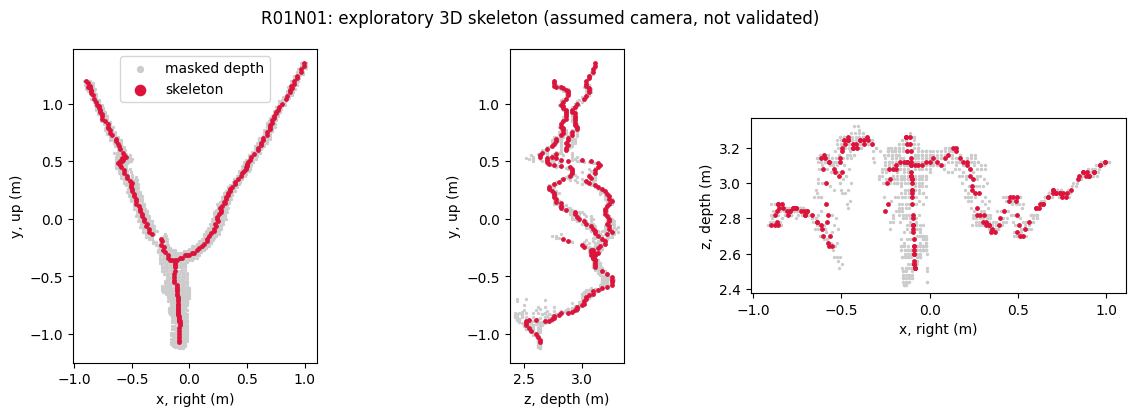

In [12]:
from google.colab import drive
drive.mount('/content/drive')

# ===== Exploratory 3D skeleton for one tree (assumed camera, NOT validated) =====
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize

CACHE = "/content/drive/MyDrive/apple_cache.npz"   # <- change if your cache is elsewhere
TREE = "R01N01"                                     # <- any tree name
HFOV_DEG, DEPTH_UNIT = 60.0, 0.02                   # ASSUMED: field of view and metres per grey level

c = np.load(CACHE, allow_pickle=True)
trees = [str(t) for t in c["trees"]]
i = trees.index(TREE)
depth = c["Xc"][i, :, :, 3].astype(float)           # 128 x 128 depth (centre crop); 0 = no measurement
mask = c["Y"][i].reshape(128, 2, 128, 2).mean(axis=(1, 3)) > 0.5   # mask shrunk to 128 x 128
skel = skeletonize(mask)                            # one-pixel centre line of the mask

# camera: HFOV applies to the full 640-pixel-wide image; the 128x128 picture is a 480x480 crop shrunk by 128/480
f = (640 / 2) / np.tan(np.radians(HFOV_DEG / 2)) * (128 / 480)
cx = cy = 64.0

def lift(pix):
    v, u = np.nonzero(pix & (depth > 0))            # drop pixels with no depth
    z = depth[v, u] * DEPTH_UNIT
    return np.column_stack([(u - cx) * z / f, -(v - cy) * z / f, z])   # x right, y up, z away from camera

pts_mask, pts_skel = lift(mask), lift(skel)
print(f"{TREE}: mask pixels {int(mask.sum())}, with valid depth {len(pts_mask)} "
      f"({100 * len(pts_mask) / max(int(mask.sum()), 1):.0f}%); skeleton points {len(pts_skel)}")

fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
views = [(0, 1, "x, right (m)", "y, up (m)"), (2, 1, "z, depth (m)", "y, up (m)"), (0, 2, "x, right (m)", "z, depth (m)")]
for a, (p, q, xl, yl) in zip(ax, views):
    a.scatter(pts_mask[:, p], pts_mask[:, q], s=2, c="0.8", label="masked depth")
    a.scatter(pts_skel[:, p], pts_skel[:, q], s=6, c="crimson", label="skeleton")
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect("equal")
ax[0].legend(markerscale=3)
fig.suptitle(f"{TREE}: exploratory 3D skeleton (assumed camera, not validated)")
plt.tight_layout(); plt.show()

**Left panel (front view):** a clean Y that follows the mask. That’s expected, because the shape comes from the hand-drawn mask.

**Middle and right panels (depth):** the red skeleton zig-zags back and forth between about 2.4 m and 3.3 m instead of running smoothly. A real branch doesn’t do that. The camera’s depth values are jumping between leaves in front of the branch and gaps behind it.

What it does, in plain words

- It takes the depth image and the hand-drawn mask for one tree and shrinks the mask to the same 128×128 size.
skeletonize thins the thick white mask down to a one-pixel centre line.

- For every skeleton pixel that has a depth value, it works out a 3D position from the pixel’s place in the image and its depth, using the camera formula in Section 3.6. Pixels with no depth are dropped.

- It draws the points from three directions: front, side and top. Grey points are the whole masked region and red points are the skeleton.

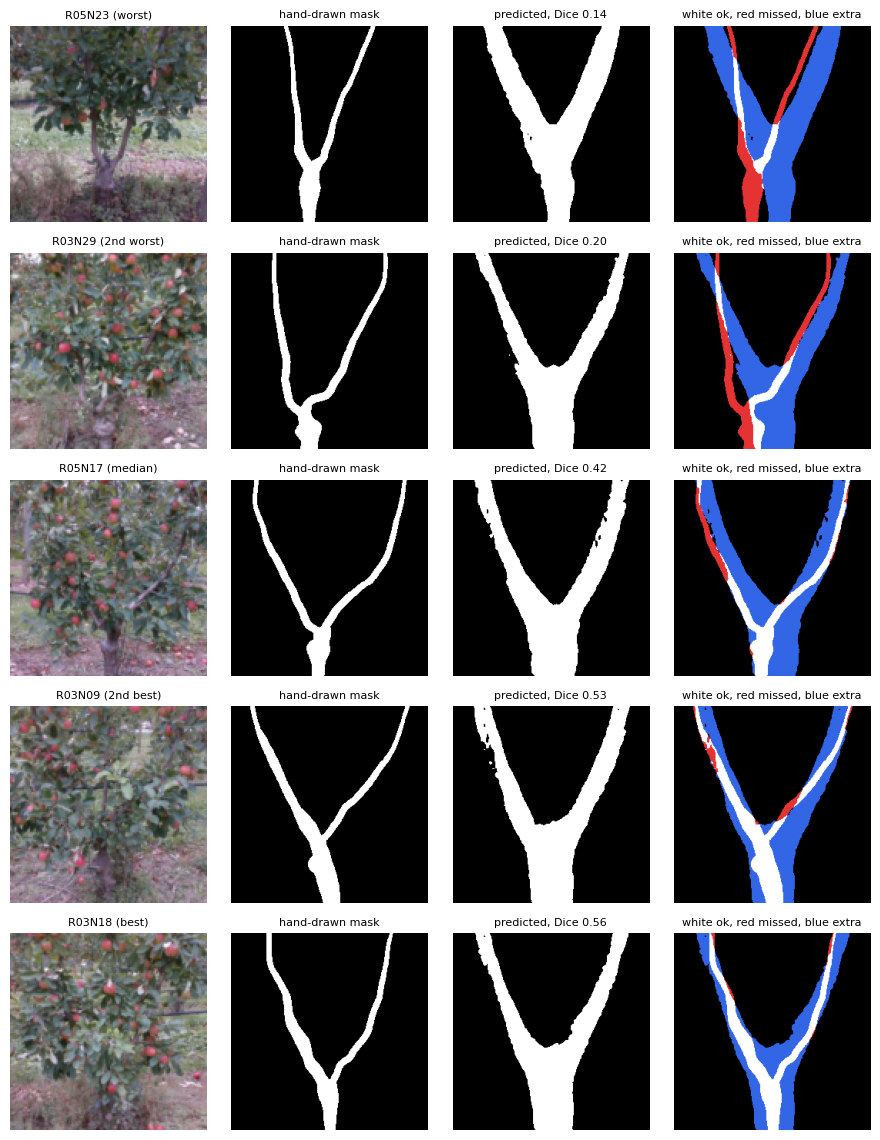

In [13]:
# ===== Figure: predictions beside the true masks (worst, median and best test trees, split 0) =====
P_te = predict(te)                           # predicted maps for the test trees (needs Step 5 to have run)
pred_masks = P_te >= thr
order = np.argsort(d_te)                     # test trees from worst to best Dice
pick = [order[0], order[1], order[len(order) // 2], order[-2], order[-1]]
labels = ["worst", "2nd worst", "median", "2nd best", "best"]

fig, ax = plt.subplots(len(pick), 4, figsize=(9, 2.3 * len(pick)))
for r, (j, lab) in enumerate(zip(pick, labels)):
    i = te[j]
    truth, pred = Yb[i], pred_masks[j]
    overlay = np.zeros(truth.shape + (3,))
    overlay[truth & pred] = [1, 1, 1]          # white  = correct
    overlay[truth & ~pred] = [0.9, 0.2, 0.2]   # red    = branch the model missed
    overlay[~truth & pred] = [0.2, 0.4, 0.9]   # blue   = branch the model invented
    ax[r, 0].imshow(X[i, :, :, :3]);  ax[r, 0].set_title(f"{trees[i]} ({lab})", fontsize=8)
    ax[r, 1].imshow(truth, cmap="gray"); ax[r, 1].set_title("hand-drawn mask", fontsize=8)
    ax[r, 2].imshow(pred, cmap="gray");  ax[r, 2].set_title(f"predicted, Dice {d_te[j]:.2f}", fontsize=8)
    ax[r, 3].imshow(overlay);            ax[r, 3].set_title("white ok, red missed, blue extra", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout()
plt.savefig("fig_predictions.png", dpi=200, bbox_inches="tight")   # saved in Colab's file panel
plt.show()

What the pictures show

- Every prediction is almost the same thick, smooth Y. The model mostly reproduces the average tree shape and adapts only a little to the photo. This is what the small +0.023 gain over the baseline looks like.
- The prediction is much wider than the real branches. The blue (extra) areas are wide bands on both sides of the thin true branches. The model hedges: it isn’t sure where the branches are, so the threshold the validation set chose (0.15) draws a broad region.
- The real branches usually fall inside the predicted band. In the best rows, the white line (correct) runs along the middle of the blue band. So the model finds the rough region well but not the branch itself, which gives a high-recall, low-precision result.
- The worst trees are the ones that differ from the average. In R05N23 and R03N29 the real fork sits lower or leans to one side, and the model draws the average fork (red = missed on the left).
- The photo clearly shows branches the model doesn’t use. The features are coarse: 16×16 blocks of colour and depth, which can’t trace a thin branch.